# KODIAK pretraining curves

What a KODIAK pretraining run did, read from what it wrote under `runs/<name>/`: Lightning's `logs/metrics.csv` (every
loss part and every schedule value at every logged step, plus the number of prototypes a batch used), the resolved
config, and the checkpoints. The run of record is `runs/kodiak_mxif_vitb` (ViT-B/16 continued from the DINOv3 ViT-B weights,
`configs/kodiak_pretrain_vitb.yaml`, LAP2 · random marker · DAPI); the architecture is read from the run's
`resolved_config.yaml`, never set here. Add any other run to `RUNS` to compare.

| figure | content |
|---|---|
| 1 | the loss parts per optimizer step, raw |
| 2 | the loss parts per epoch, and how many of the 128 prototypes a batch uses (the collapse diagnostic) |
| 3 | the schedules as applied — learning rates, weight decay, EMA momentum, teacher temperature — against the config |
| 4 | the codebook at each checkpoint: how tokens of held-out patches spread over the prototypes |

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
import json, math, os, shutil, tempfile, time
from pathlib import Path
import numpy as np, pandas as pd, torch, yaml
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from mxdata import DEFAULT_DATASET, load_config

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# ---- edit here ---------------------------------------------------------------------------------------------------------
RUNS = {"KODIAK ViT-B/16 (LAP2 · random marker · DAPI)": REPO / "runs" / "kodiak_mxif_vitb"}      # label -> run directory; missing runs are skipped
RUN_COLOR = ["#C43E4E", "#8A8A8A", "#B08A2E", "#2A78D6"]
STEP_SMOOTH = 0                                 # figure 1: 0 = raw; n = centred moving average over n logged steps
N_PATCHES = 64                                  # figure 4: validation patches encoded per checkpoint (CPU)
GREEN = "PanCK"                                 # figure 4: the marker read into green for a run that draws it at random
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PARTS = {"train_loss": "total", "train_mask": "masked prototype", "train_proto_cls": "prototype-CLS", "train_koleo": "KoLeo"}

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def epoch_axis(ax):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

def finish(fig, handles=None, ncol=3):
    if handles:
        fig.legend(handles=handles, ncol=min(ncol, len(handles)), loc="lower center", bbox_to_anchor=(0.5, -0.01), fontsize=7.4, handlelength=1.8, columnspacing=1.2)
    plt.show()

class Run:
    """One pretraining run: its per-step and per-epoch tables (Lightning's sparse CSV split by column suffix), config, checkpoints."""
    def __init__(self, label, path, color):
        self.label, self.path, self.color = label, Path(path), color
        self.cfg = yaml.safe_load((self.path / "resolved_config.yaml").read_text())
        raw = pd.read_csv(self.path / "logs" / "metrics.csv")
        step_cols = [c for c in raw.columns if c.endswith("_step")]
        epoch_cols = [c for c in raw.columns if c.endswith("_epoch")]
        self.steps = raw.dropna(subset=step_cols, how="all")[["step", "epoch", *step_cols]].rename(columns=lambda c: c.removesuffix("_step"))
        self.epochs = (raw.dropna(subset=epoch_cols, how="all").dropna(subset=["epoch"])[["epoch", *epoch_cols]]
                       .groupby("epoch").max().rename(columns=lambda c: c.removesuffix("_epoch")).reset_index())
        self.epochs["epoch"] = self.epochs["epoch"].astype(int)
        self.checkpoints = sorted((self.path / "checkpoints").glob("kodiak-epoch=*.ckpt")) + [p for p in [self.path / "checkpoints" / "last.ckpt"] if p.is_file()]
        d = self.cfg.get("data", {})
        if "input" in d:                                                   # the run of record: fixed red / blue, green drawn per sample
            self.channels = (d["input"]["red"], GREEN, d["input"]["blue"])
            self.input_text = f"R {d['input']['red']} · G drawn per sample · B {d['input']['blue']}"
        else:                                                              # an older run configured with data.markers: one marker per channel
            self.channels = tuple(d.get("markers", ["CD45", "PanCK", "DAPI"]))
            self.input_text = " · ".join(self.channels)
    @property
    def planned(self): return int(self.cfg.get("training", {}).get("max_epochs", 0))
    @property
    def done(self): return int(self.epochs["epoch"].max()) + 1 if len(self.epochs) else 0
    def handle(self):
        return plt.Line2D([], [], color=self.color, lw=1.6, label=self.label)

runs = [Run(k, p, RUN_COLOR[i]) for i, (k, p) in enumerate(RUNS.items()) if (Path(p) / "logs" / "metrics.csv").is_file()]
missing = [k for k, p in RUNS.items() if not (Path(p) / "logs" / "metrics.csv").is_file()]
if not runs:
    raise FileNotFoundError("no pretraining run with logs: python -m kodiak.pretrain --config configs/kodiak_pretrain.yaml")
if missing:
    print("not available yet:", "; ".join(missing))
HANDLES = [r.handle() for r in runs]
rows = []
for r in runs:
    m, o, a = r.cfg.get("model", {}), r.cfg.get("optimizer", {}), r.cfg.get("data", {}).get("augmentation", {})
    last = r.epochs.iloc[-1]
    rows.append({"run": r.label, "input": r.input_text, "epochs": f"{r.done} / {r.planned}", "steps": int(r.steps["step"].max()) + 1,
                 "batch": r.cfg.get("data", {}).get("batch_size"), "local crops": a.get("local_crops_number"), "prototypes": m.get("num_prototypes"),
                 "mask ratio": tuple(m.get("mask_ratio_min_max", ())), "peak lr": o.get("learning_rate"), "wd": f"{o.get('weight_decay')} -> {o.get('weight_decay_end')}",
                 "loss (last epoch)": round(float(last.get("train_loss", np.nan)), 3), "mask": round(float(last.get("train_mask", np.nan)), 3),
                 "proto-CLS": round(float(last.get("train_proto_cls", np.nan)), 3), "prototypes used / batch": round(float(last.get("train_util", np.nan)), 1),
                 "checkpoints": len(r.checkpoints)})
display(pd.DataFrame(rows).set_index("run").T)

run,KODIAK ViT-B/16 (LAP2 · random marker · DAPI)
input,R LAP2 · G drawn per sample · B DAPI
epochs,66 / 100
steps,41980
batch,8
local crops,4
prototypes,128
mask ratio,"(0.1, 0.5)"
peak lr,0.0001
wd,0.04 -> 0.4
loss (last epoch),3.09


## 1. The loss parts per step

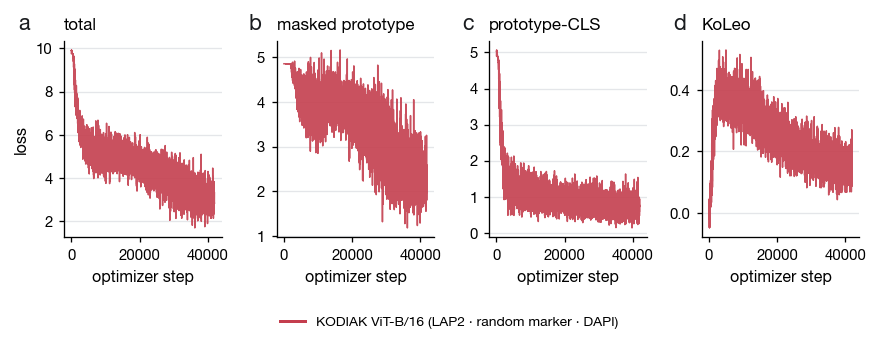

In [2]:
present = [p for p in PARTS if any(p in r.steps for r in runs)]
fig, axes = plt.subplots(1, len(present), figsize=(7.6, 2.5))
for ax, part in zip(np.atleast_1d(axes), present):
    for r in runs:
        if part in r.steps:
            s = r.steps.dropna(subset=[part])
            y = s[part].rolling(STEP_SMOOTH, center=True, min_periods=1).mean() if STEP_SMOOTH > 1 else s[part]
            ax.plot(s["step"], y, lw=0.8, color=r.color, alpha=0.9)
    ax.set_title(PARTS[part]); ax.set_xlabel("optimizer step"); ygrid(ax)
np.atleast_1d(axes)[0].set_ylabel("loss" + (f" (moving average, {STEP_SMOOTH})" if STEP_SMOOTH > 1 else ""))
for ax, letter in zip(np.atleast_1d(axes), "abcd"):
    panel(ax, letter, dx=-0.22 if ax is np.atleast_1d(axes)[0] else -0.1)
fig.subplots_adjust(bottom=0.3, wspace=0.35)
finish(fig, HANDLES)

**Figure 1 — The loss parts per optimizer step**, raw as logged (every tenth step). Total = masked prototype prediction
(the student predicts the teacher's Sinkhorn-balanced prototype assignment of masked patch tokens) + the multi-crop
prototype-CLS alignment (global and local crops against the same codebook) + 0.1 × KoLeo (a uniformity term on the
CLS embeddings). The prototype losses are cross-entropies against 128-way targets: their floor is set by the teacher
temperature, not by zero.

## 2. Per epoch, and how much of the codebook a batch uses

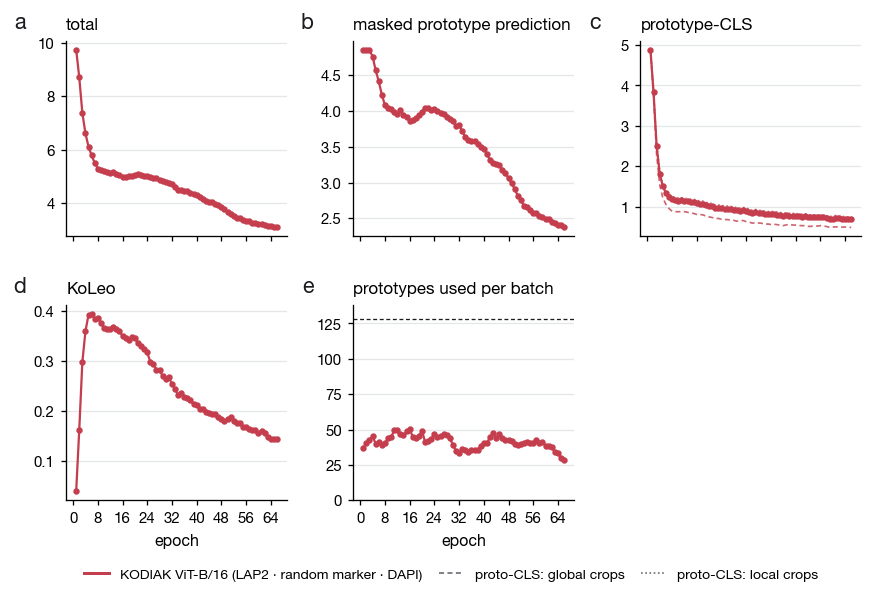

In [3]:
keys = [("train_loss", "total"), ("train_mask", "masked prototype prediction"), ("train_proto_cls", "prototype-CLS"),
        ("train_koleo", "KoLeo"), ("train_util", "prototypes used per batch")]
fig, axes = plt.subplots(2, 3, figsize=(7.6, 4.6), sharex=True)
for ax, (k, title) in zip(axes.ravel(), keys):
    for r in runs:
        if k in r.epochs:
            ax.plot(r.epochs["epoch"] + 1, r.epochs[k], marker="o", ms=2.4, lw=1.2, color=r.color)
            if k == "train_proto_cls" and "train_cls_local" in r.epochs:
                ax.plot(r.epochs["epoch"] + 1, r.epochs["train_cls_global"], lw=0.9, ls=(0, (3, 2)), color=r.color, alpha=0.8)
                ax.plot(r.epochs["epoch"] + 1, r.epochs["train_cls_local"], lw=0.9, ls=(0, (1, 1.5)), color=r.color, alpha=0.8)
    if k == "train_util":
        n_proto = max(int(r.cfg.get("model", {}).get("num_prototypes", 128)) for r in runs)
        ax.axhline(n_proto, color=INK, lw=0.7, ls=(0, (3, 2))); ax.set_ylim(0, n_proto * 1.08)
    ax.set_title(title); ygrid(ax); epoch_axis(ax)
axes.ravel()[-1].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("epoch")
for ax, letter in zip(axes.ravel(), "abcde"):
    panel(ax, letter, dx=-0.18)
extra = [plt.Line2D([], [], color=MUTED, lw=0.9, ls=(0, (3, 2)), label="proto-CLS: global crops"), plt.Line2D([], [], color=MUTED, lw=0.9, ls=(0, (1, 1.5)), label="proto-CLS: local crops")]
fig.subplots_adjust(bottom=0.14, hspace=0.35, wspace=0.3)
finish(fig, HANDLES + extra, ncol=4)

**Figure 2 — Per epoch.** (a–d) Epoch means of the loss parts; the prototype-CLS panel also shows its global-crop and
local-crop halves. (e) How many of the 128 prototypes the tokens of a batch are assigned to (mean over the epoch's
batches, logged by the learner): the dashed line is the full codebook. A codebook that stays far below it is partially
collapsed — few prototypes receive most tokens — which is what Sinkhorn balancing of the *targets* counteracts and what
the temperature warm-up in Figure 3 governs.

## 3. The schedules as applied

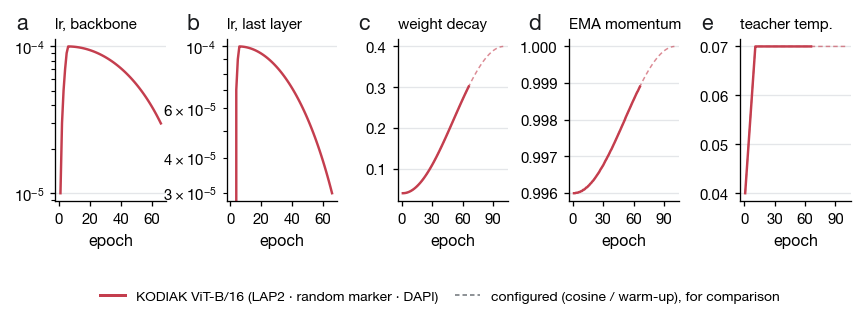

In [4]:
from kodiak.learner import cosine_schedule

SCHED = [("lr", "lr, backbone"), ("last_layer_lr", "lr, last layer"), ("wd", "weight decay"), ("mom", "EMA momentum"), ("teacher_temp", "teacher temp.")]
fig, axes = plt.subplots(1, 5, figsize=(7.6, 2.3))
for ax, (k, title) in zip(axes, SCHED):
    for r in runs:
        if k in r.epochs:
            ax.plot(r.epochs["epoch"] + 1, r.epochs[k], lw=1.3, color=r.color)
        o, E = r.cfg.get("optimizer", {}), r.planned                        # the configured schedule, for comparison
        ep = np.arange(E)
        if k == "wd":
            ax.plot(ep + 1, [cosine_schedule(o.get("weight_decay", 0.04), o.get("weight_decay_end", 0.4), E)(e) for e in ep], lw=0.8, ls=(0, (3, 2)), color=r.color, alpha=0.6)
        if k == "mom":
            ax.plot(ep + 1, [cosine_schedule(o.get("ema_momentum", 0.996), o.get("ema_momentum_end", 1.0), E)(e) for e in ep], lw=0.8, ls=(0, (3, 2)), color=r.color, alpha=0.6)
        if k == "teacher_temp":
            t0, t1, w = o.get("teacher_temp_warmup", 0.04), o.get("teacher_temp", 0.07), o.get("teacher_temp_warmup_epochs", 10)
            ax.plot(ep + 1, [t0 + (t1 - t0) * (e / w) if e < w else t1 for e in ep], lw=0.8, ls=(0, (3, 2)), color=r.color, alpha=0.6)
    ax.set_title(title, fontsize=8); ax.set_xlabel("epoch"); ygrid(ax); ax.xaxis.set_major_locator(MaxNLocator(4, integer=True))
    if k in ("lr", "last_layer_lr"):
        ax.set_yscale("log")
for ax, letter in zip(axes, "abcde"):
    panel(ax, letter, dx=-0.25)
fig.subplots_adjust(bottom=0.36, wspace=0.55)
finish(fig, HANDLES + [plt.Line2D([], [], color=MUTED, lw=0.8, ls=(0, (3, 2)), label="configured (cosine / warm-up), for comparison")], ncol=3)

**Figure 3 — The schedules, as applied.** Epoch means of the values the learner logged at every step: the backbone
learning rate (warm-up, then cosine to the minimum), the last-layer rate (held at zero for the first epochs, DINO's
`freeze_last_layer_epochs`), the weight decay (cosine up), the EMA momentum of the teacher (cosine to 1) and the teacher
temperature (linear warm-up, then constant). Dashed: the same schedules recomputed from the run's config over its planned
length — where a run was stopped early, the solid curves end where it stopped, on schedule.

## 4. The codebook at each checkpoint

KODIAK ViT-B/16 (LAP2 · random marker · DAPI) — kodiak-epoch=024.ckpt (epoch 24): 61/128 prototypes active on 64 val patches, perplexity 4.6 (35 s)


KODIAK ViT-B/16 (LAP2 · random marker · DAPI) — kodiak-epoch=049.ckpt (epoch 49): 61/128 prototypes active on 64 val patches, perplexity 17.2 (27 s)


KODIAK ViT-B/16 (LAP2 · random marker · DAPI) — last.ckpt (epoch 65): 52/128 prototypes active on 64 val patches, perplexity 7.1 (31 s)


epoch  \
run                                           checkpoint                     
KODIAK ViT-B/16 (LAP2 · random marker · DAPI) kodiak-epoch=024.ckpt     24   
                                              kodiak-epoch=049.ckpt     49   
                                              last.ckpt                 65   

                                                                     active codes  \
run                                           checkpoint                            
KODIAK ViT-B/16 (LAP2 · random marker · DAPI) kodiak-epoch=024.ckpt            61   
                                              kodiak-epoch=049.ckpt            61   
                                              last.ckpt                        52   

                                                                     codes for 90 % of tokens  \
run                                           checkpoint                                        
KODIAK ViT-B/16 (LAP2 · random marker · DAPI) kodiak-epoch=024.ckpt                        11   
                                              kodiak-epoch=049.ckpt                        20   
                                              last.ckpt                                     6   

                                                                     perplexity  \
run                                           checkpoint                          
KODIAK ViT-B/16 (LAP2 · random marker · DAPI) kodiak-epoch=024.ckpt         4.6   
                                              kodiak-epoch=049.ckpt        17.2   
                                              last.ckpt                     7.1   

                                                                    top code share  
run                                           checkpoint                            
KODIAK ViT-B/16 (LAP2 · random marker · DAPI) kodiak-epoch=024.ckpt            70%  
                                              kodiak-epoch=049.ckpt            25%  
                                              last.ckpt                        26%

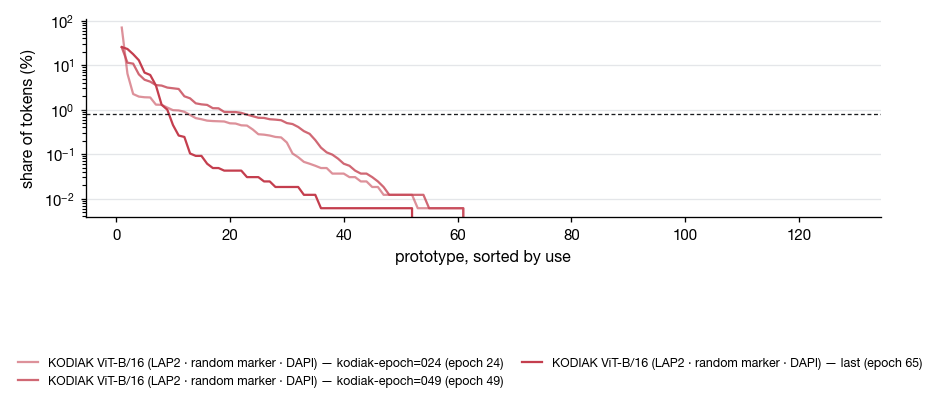

In [5]:
from kodiak import Kodiak
from mxdata.data import PatchSource
from mxdata.data.composite import render_channels
from mxseg.inputs import dataset_norms

IN_MEAN = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]
IN_STD = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]
torch.set_grad_enabled(False)
torch.set_num_threads(max(2, (os.cpu_count() or 8) // 2))
src = PatchSource(DEFAULT_DATASET, split="val", kind="labeled")
keys = src.keys[:N_PATCHES]

def load_model(run, ckpt):
    m = run.cfg.get("model", {})
    net = Kodiak(num_prototypes=m.get("num_prototypes", 128), projector_dim=m.get("projector_dim", 256), img_size=m.get("image_size", 256),
                 patch_size=m.get("vit_patch_size", 16), embed_dim=m.get("vit_embed_dim", 384), depth=m.get("vit_depth", 12),
                 num_heads=m.get("vit_heads", 6), mlp_ratio=m.get("vit_mlp_ratio", 4.0), num_storage_tokens=m.get("num_storage_tokens", 4),
                 decoder_embed_dim=m.get("decoder_dim", 192), decoder_depth=m.get("decoder_depth", 4), decoder_num_heads=m.get("decoder_heads", 6)).eval()
    tmp = Path(tempfile.gettempdir()) / "kodiak_curves.ckpt"
    shutil.copy2(ckpt, tmp)                                                # last.ckpt is rewritten at every epoch end of a live run
    ck = torch.load(tmp, map_location="cpu", weights_only=False)
    state = {k.split("model.", 1)[1]: v for k, v in ck["state_dict"].items() if k.startswith("model.")}
    missing, _ = net.load_state_dict(state, strict=False)
    assert not [k for k in missing if "teacher" in k or "prototype" in k], missing
    return net, int(ck["epoch"])

usage, rows = {}, []
for r in runs:
    if not r.checkpoints:
        print(f"{r.label}: no checkpoints"); continue
    markers = [m for m in r.channels if m]
    slide = src.row(keys[0])["slide"]
    norms = dataset_norms(DEFAULT_DATASET, [slide], markers)[slide]
    xb = torch.from_numpy(np.stack([(render_channels(src.load(k).image, src.markers, norms, r.channels) - IN_MEAN) / IN_STD for k in keys]))
    for ckpt in r.checkpoints:
        t0 = time.perf_counter()
        net, epoch = load_model(r, ckpt)
        codes = np.concatenate([net.forward_features(xb[i:i + 8], use_teacher=True)[1].argmax(-1).numpy().ravel() for i in range(0, len(xb), 8)])
        counts = np.bincount(codes, minlength=net.prototype_layer.layer.weight.shape[0])
        p = counts / counts.sum()
        H = -(p[p > 0] * np.log(p[p > 0])).sum()
        usage[(r.label, epoch, ckpt.stem)] = np.sort(counts)[::-1] / counts.sum()
        rows.append({"run": r.label, "checkpoint": ckpt.name, "epoch": epoch, "active codes": int((counts > 0).sum()), "codes for 90 % of tokens": int((np.cumsum(np.sort(p)[::-1]) < 0.9).sum()) + 1,
                     "perplexity": round(float(np.exp(H)), 1), "top code share": f"{p.max():.0%}"})
        print(f"{r.label} — {ckpt.name} (epoch {epoch}): {int((counts > 0).sum())}/{len(counts)} prototypes active on {len(keys)} val patches, perplexity {np.exp(H):.1f} ({time.perf_counter() - t0:.0f} s)")
table = pd.DataFrame(rows)
if len(table):
    display(table.set_index(["run", "checkpoint"]))
    fig, ax = plt.subplots(figsize=(7.6, 3.2))
    fig.subplots_adjust(bottom=0.42)
    for r in runs:
        keys_r = [k for k in usage if k[0] == r.label]
        for j, (lab, e, name) in enumerate(keys_r):
            u = usage[(lab, e, name)]
            ax.plot(np.arange(1, len(u) + 1), 100 * u, lw=1.2, color=r.color, alpha=0.35 + 0.65 * (j + 1) / len(keys_r), label=f"{r.label} — {name} (epoch {e})")
    ax.axhline(100 / len(u), color=INK, lw=0.7, ls=(0, (3, 2)))
    ax.set_xlabel("prototype, sorted by use"); ax.set_ylabel("share of tokens (%)"); ax.set_yscale("log"); ygrid(ax)
    fig.legend(fontsize=6.6, ncol=2, handlelength=1.6, loc="lower center", bbox_to_anchor=(0.5, 0.0), columnspacing=1.5)
    plt.show()

**Figure 4 — The codebook at each checkpoint.** For every checkpoint of a run, the EMA teacher assigns each 16-px token of
64 held-out validation patches to its nearest prototype; the curve is the share of tokens per prototype, sorted, and the
dashed line is perfect balance (1/128). The table gives the number of prototypes used at all, the number covering 90 % of
the tokens, and the perplexity of the usage distribution — the effective codebook size. The input rendered here follows
each run's own recipe; for the run of record the green channel is fixed to one marker (`GREEN`), one of its pretraining
draws.